# Tiền xử lý dữ liệu, nhiều cách chia tập và so sánh mô hình

Notebook này bổ sung ba yêu cầu bắt buộc của đề tài:

1. Đánh giá bằng Accuracy, Precision, Recall, F1-score, AP/chất lượng xếp hạng, số cảnh báo và thời gian thực thi.
2. So sánh nhiều tỷ lệ chia dữ liệu: 6/2/2, 7/1.5/1.5, 8/1/1, 7.5/1.5/1 và 5/2.5/2.5.
3. Giải thích từng bước tiền xử lý: làm gì, vì sao cần làm và kiểm soát rò rỉ dữ liệu như thế nào.

HCO, VNLS và HCO+VNLS vẫn là trọng tâm thuật toán. Các model dưới đây là model học máy dùng làm baseline và bộ chấm nghiệm feature.


## 1. Vì sao phải tiền xử lý?

| Bước | Làm gì | Vì sao cần làm | Kiểm soát rủi ro |
|---|---|---|---|
| Đọc 7 bảng OULAD | Đọc thông tin sinh viên, đăng ký, đánh giá, nộp bài, VLE, site và khóa học | Mỗi bảng chỉ chứa một phần hành vi; cần ghép để có đủ bối cảnh | Kiểm tra schema và khóa trước khi ghép |
| Gộp theo enrollment | Dùng `id_student + code_module + code_presentation` | Một sinh viên có thể học nhiều module/kỳ; không được trộn các enrollment | Dùng `validate='one_to_one'` hoặc `many_to_one` |
| Tạo cutoff | Chỉ giữ thông tin có trước mốc 50% tiến trình | Dự đoán tại thời điểm hiện tại không được nhìn thấy tương lai | Kiểm tra ngày hoạt động và ngày nộp bài không vượt `t` |
| Tạo nhãn | `Fail/Withdrawn -> risk=1`, `Pass/Distinction -> risk=0` | Chuyển kết quả cuối thành bài toán phân loại nguy cơ | Giữ lại `final_result` để truy vết nhưng không đưa vào feature |
| Xử lý thiếu | Số hoạt động thiếu điền 0; số liên tục dùng median; biến phân loại dùng mode | Thiếu hoạt động thường có nghĩa là chưa ghi nhận hành vi; model không nhận NaN tùy ý | Imputer nằm trong pipeline và fit trên train |
| Mã hóa phân loại | One-hot các cột như module, region, education | Model cần số; one-hot không áp đặt thứ tự giả | `handle_unknown='ignore'` cho nhóm mới ở validation/test |
| Chuẩn hóa | Chỉ scale cho Logistic Regression | Mô hình tuyến tính nhạy với độ lớn biến; cây thường không cần scale | Scaler nằm trong pipeline, chỉ fit trên train |
| Chia theo sinh viên | Train/validation/test không dùng chung `id_student` | Tránh model học thuộc sinh viên xuất hiện ở tập khác | Kiểm tra giao nhau của các group |


In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists() and (ROOT.parent / 'clht_code').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from clht_code.models import configs, feature_columns, make_pipeline
from clht_code.data import create_asof
from clht_code.evaluation import metric_table, risk_probability

OUT = ROOT / 'ket_qua'
OUT.mkdir(exist_ok=True)
asof_path = OUT / 'du_lieu_cutoff_50.csv'
if asof_path.exists():
    frame = pd.read_csv(asof_path)
else:
    frame = create_asof(DATA, 0.5, 'fraction', 'strict')
    frame.to_csv(asof_path, index=False, encoding='utf-8-sig')
feature_cols = feature_columns(frame)
X = frame[feature_cols].copy()
y = frame['risk'].astype(int).to_numpy()
print({'rows': len(frame), 'feature_count': len(feature_cols), 'risk_rate': float(y.mean())})


{'rows': 24599, 'feature_count': 27, 'risk_rate': 0.37456807187284036}


In [2]:
preprocessing_audit = pd.DataFrame([
    ['Nguồn dữ liệu', '7 bảng OULAD được đọc và giữ bản gốc', 'Giữ đầy đủ nguồn để truy vết và tái lập', 'Kiểm tra tên file, cột và SHA-256'],
    ['Khóa ghép', 'id_student + code_module + code_presentation', 'Phân biệt enrollment, không trộn các kỳ học', 'Kiểm tra validate khi merge'],
    ['Cutoff', 'Dữ liệu đến 50% tiến trình', 'Mô phỏng dự đoán tại thời điểm hiện tại', 'Không lấy sự kiện sau ngày cutoff'],
    ['Nhãn', 'Fail/Withdrawn = 1; Pass/Distinction = 0', 'Biến bài toán thành dự đoán risk', 'Không đưa final_result vào feature'],
    ['Missing hoạt động', 'Điền 0 cho biến đếm', 'Không có bản ghi hoạt động được hiểu là chưa ghi nhận hoạt động', 'Kiểm tra phân biệt 0 thật và thiếu nếu dữ liệu mới thay đổi'],
    ['Missing số liên tục', 'Median imputer trong pipeline', 'Ổn định hơn mean khi có ngoại lệ', 'Chỉ fit trên train'],
    ['Biến phân loại', 'Most-frequent imputer + OneHotEncoder', 'Model cần số và không nên tạo thứ tự giả', 'handle_unknown=ignore'],
    ['Scale', 'StandardScaler cho Logistic Regression', 'Đưa biến về thang đo tương đương', 'Không scale bắt buộc cho model cây'],
    ['Group split', 'Chia theo id_student', 'Tránh leakage giữa các enrollment của một sinh viên', 'Assert group disjoint'],
], columns=['step','implementation','why','control'])
preprocessing_audit.to_csv(OUT / 'kiem_tra_tien_xu_ly.csv', index=False, encoding='utf-8-sig')
display(preprocessing_audit)


,step,implementation,why,control
0,Nguồn dữ liệu,7 bảng OULAD được đọc và giữ bản gốc,Giữ đầy đủ nguồn để truy vết và tái lập,"Kiểm tra tên file, cột và SHA-256"
1,Khóa ghép,id_student + code_module + code_presentation,"Phân biệt enrollment, không trộn các kỳ học",Kiểm tra validate khi merge
2,Cutoff,Dữ liệu đến 50% tiến trình,Mô phỏng dự đoán tại thời điểm hiện tại,Không lấy sự kiện sau ngày cutoff
3,Nhãn,Fail/Withdrawn = 1; Pass/Distinction = 0,Biến bài toán thành dự đoán risk,Không đưa final_result vào feature
4,Missing hoạt động,Điền 0 cho biến đếm,Không có bản ghi hoạt động được hiểu là chưa g...,Kiểm tra phân biệt 0 thật và thiếu nếu dữ liệu...
5,Missing số liên tục,Median imputer trong pipeline,Ổn định hơn mean khi có ngoại lệ,Chỉ fit trên train
6,Biến phân loại,Most-frequent imputer + OneHotEncoder,Model cần số và không nên tạo thứ tự giả,handle_unknown=ignore
7,Scale,StandardScaler cho Logistic Regression,Đưa biến về thang đo tương đương,Không scale bắt buộc cho model cây
8,Group split,Chia theo id_student,Tránh leakage giữa các enrollment của một sinh...,Assert group disjoint


## 2. Hàm chia nhóm theo tỷ lệ

Các tỷ lệ được ghi theo thứ tự **train/validation/test**. Ví dụ 6/2/2 nghĩa là 60% train, 20% validation và 20% test. Vì chia theo group nên số dòng thực tế có thể lệch nhẹ, nhưng sinh viên không bị tách sang nhiều tập.


In [3]:
def split_by_ratio(frame, train_fraction, validation_fraction, test_fraction, seed=41):
    total = train_fraction + validation_fraction + test_fraction
    if not np.isclose(total, 1.0):
        raise ValueError('Các tỷ lệ phải cộng bằng 1')
    groups = frame['id_student'].to_numpy()
    indices = np.arange(len(frame))
    first = GroupShuffleSplit(n_splits=1, test_size=1 - train_fraction, random_state=seed)
    train_idx, holdout_idx = next(first.split(indices, groups=groups))
    test_fraction_in_holdout = test_fraction / (validation_fraction + test_fraction)
    second = GroupShuffleSplit(n_splits=1, test_size=test_fraction_in_holdout, random_state=seed + 1)
    validation_rel, test_rel = next(second.split(holdout_idx, groups=groups[holdout_idx]))
    validation_idx = holdout_idx[validation_rel]
    test_idx = holdout_idx[test_rel]
    split_groups = [set(frame.iloc[idx]['id_student']) for idx in [train_idx, validation_idx, test_idx]]
    assert not (split_groups[0] & split_groups[1] or split_groups[0] & split_groups[2] or split_groups[1] & split_groups[2])
    return train_idx, validation_idx, test_idx

ratios = {
    '6/2/2': (0.60, 0.20, 0.20),
    '7/1.5/1.5': (0.70, 0.15, 0.15),
    '8/1/1': (0.80, 0.10, 0.10),
    '7.5/1.5/1': (0.75, 0.15, 0.10),
    '5/2.5/2.5': (0.50, 0.25, 0.25),
}


## 3. Bảng so sánh model học máy

Bảng này dùng toàn bộ feature làm mốc. Sau đó HCO/VNLS/HCO+VNLS sẽ tìm mask và dùng chính các metric này để so sánh nghiệm.


In [4]:
model_map = {cfg.name: cfg for cfg in configs(41)}
model_names = ['LogisticRegression', 'DecisionTree', 'RandomForest', 'ExtraTrees', 'HistGradientBoosting']
rows = []
for ratio_name, ratio_values in ratios.items():
    train_idx, validation_idx, test_idx = split_by_ratio(frame, *ratio_values, seed=41)
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    for model_name in model_names:
        config = model_map[model_name]
        started = time.perf_counter()
        pipeline = make_pipeline(X_train, config)
        pipeline.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - started
        inference_started = time.perf_counter()
        probabilities = risk_probability(pipeline, X_test)
        inference_seconds = time.perf_counter() - inference_started
        metrics = metric_table(y_test, probabilities, threshold=0.5)
        rows.append({
            'split_ratio': ratio_name, 'model': model_name,
            'train_rows': len(train_idx), 'validation_rows': len(validation_idx), 'test_rows': len(test_idx),
            'accuracy': metrics['accuracy'], 'precision_risk': metrics['precision_risk'],
            'recall_risk': metrics['recall_risk'], 'f1_risk': metrics['f1_risk'],
            'weighted_f1': metrics['weighted_f1'], 'average_precision_risk': metrics['average_precision_risk'],
            'roc_auc': metrics['roc_auc'], 'brier_score': metrics['brier_score'],
            'alerts': metrics['alerts'], 'fit_seconds': fit_seconds, 'inference_seconds': inference_seconds,
            'total_seconds': fit_seconds + inference_seconds
        })

split_model_results = pd.DataFrame(rows)
split_model_results.to_csv(OUT / 'so_sanh_mo_hinh_theo_ty_le_chia.csv', index=False, encoding='utf-8-sig')
display(split_model_results.round(4))


,split_ratio,model,train_rows,validation_rows,test_rows,accuracy,precision_risk,recall_risk,f1_risk,weighted_f1,average_precision_risk,roc_auc,brier_score,alerts,fit_seconds,inference_seconds,total_seconds
0,6/2/2,LogisticRegression,14774,4908,4917,0.8035,0.7521,0.7215,0.7365,0.8027,0.8471,0.8742,0.1375,1795,0.2889,0.0319,0.3208
1,6/2/2,DecisionTree,14774,4908,4917,0.7956,0.7506,0.6932,0.7208,0.7939,0.8074,0.8327,0.1537,1728,0.2892,0.0193,0.3085
2,6/2/2,RandomForest,14774,4908,4917,0.8192,0.8448,0.6430,0.7302,0.8131,0.8476,0.8689,0.1327,1424,2.3868,0.0686,2.4554
3,6/2/2,ExtraTrees,14774,4908,4917,0.8127,0.8109,0.6622,0.7290,0.8082,0.8467,0.8670,0.1352,1528,2.1023,0.0763,2.1786
4,6/2/2,HistGradientBoosting,14774,4908,4917,0.8220,0.8603,0.6355,0.7310,0.8153,0.8564,0.8771,0.1277,1382,2.9783,0.0451,3.0234
5,7/1.5/1.5,LogisticRegression,17246,3684,3669,0.7999,0.7447,0.7267,0.7356,0.7995,0.8434,0.8674,0.1412,1371,0.2866,0.0152,0.3018
6,7/1.5/1.5,DecisionTree,17246,3684,3669,0.7885,0.7403,0.6897,0.7141,0.7870,0.8144,0.8382,0.1522,1309,0.2388,0.0149,0.2537
7,7/1.5/1.5,RandomForest,17246,3684,3669,0.8155,0.8421,0.6377,0.7258,0.8092,0.8483,0.8657,0.1337,1064,2.3258,0.0668,2.3925
8,7/1.5/1.5,ExtraTrees,17246,3684,3669,0.8106,0.8050,0.6669,0.7295,0.8065,0.8448,0.8629,0.1367,1164,2.5063,0.0933,2.5995
9,7/1.5/1.5,HistGradientBoosting,17246,3684,3669,0.8155,0.8421,0.6377,0.7258,0.8092,0.8520,0.8701,0.1313,1064,0.7789,0.0320,0.8110


,split_ratio,model,accuracy,precision_risk,recall_risk,f1_risk,weighted_f1,average_precision_risk,total_seconds
24,5/2.5/2.5,HistGradientBoosting,0.8117,0.8352,0.6158,0.7089,0.8042,0.8392,0.8190
20,5/2.5/2.5,LogisticRegression,0.7970,0.7373,0.7067,0.7217,0.7961,0.8327,0.2410
4,6/2/2,HistGradientBoosting,0.8220,0.8603,0.6355,0.7310,0.8153,0.8564,3.0234
2,6/2/2,RandomForest,0.8192,0.8448,0.6430,0.7302,0.8131,0.8476,2.4554
19,7.5/1.5/1,HistGradientBoosting,0.8125,0.8508,0.6255,0.7210,0.8054,0.8526,0.8342
17,7.5/1.5/1,RandomForest,0.8105,0.8438,0.6266,0.7191,0.8036,0.8483,2.4669
9,7/1.5/1.5,HistGradientBoosting,0.8155,0.8421,0.6377,0.7258,0.8092,0.8520,0.8110
7,7/1.5/1.5,RandomForest,0.8155,0.8421,0.6377,0.7258,0.8092,0.8483,2.3925
14,8/1/1,HistGradientBoosting,0.8063,0.8364,0.6189,0.7114,0.7991,0.8470,0.8442
13,8/1/1,ExtraTrees,0.7924,0.7771,0.6476,0.7064,0.7881,0.8362,2.7859


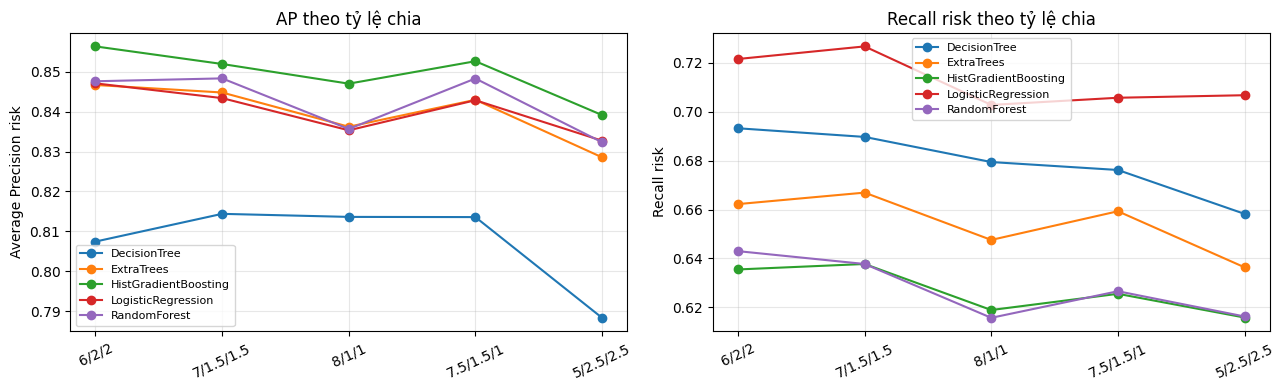

In [5]:
best_by_ratio = (split_model_results.sort_values(['split_ratio','average_precision_risk'], ascending=[True,False])
                 .groupby('split_ratio', as_index=False).head(2))
display(best_by_ratio[['split_ratio','model','accuracy','precision_risk','recall_risk','f1_risk','weighted_f1','average_precision_risk','total_seconds']].round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for model_name, group in split_model_results.groupby('model'):
    ordered = group.set_index('split_ratio').reindex(ratios.keys())
    axes[0].plot(ordered.index, ordered['average_precision_risk'], marker='o', label=model_name)
    axes[1].plot(ordered.index, ordered['recall_risk'], marker='o', label=model_name)
axes[0].set_title('AP theo tỷ lệ chia')
axes[0].set_ylabel('Average Precision risk')
axes[1].set_title('Recall risk theo tỷ lệ chia')
axes[1].set_ylabel('Recall risk')
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(OUT / 'so_sanh_ty_le_chia_tap.png', dpi=160)
plt.show()


## 4. Liên hệ với HCO, VNLS và HCO+VNLS

Kết quả baseline ở trên trả lời: model học máy nào có nền tốt. Kết quả notebook 10 trả lời: với cùng model, phương pháp chọn feature nào tốt hơn. Hai bảng cần được đặt cạnh nhau trong luận văn:

- Baseline: full features, nhiều tỷ lệ chia và đầy đủ metric.
- Metaheuristic: HCO, VNLS, HCO+VNLS, cùng model, cùng split, cùng ngân sách.
- Kết luận: HCO+VNLS chỉ được gọi là cải thiện khi ưu thế lặp lại qua seed và không đánh đổi bằng ngân sách lớn hơn.

Các kết quả HCO/VNLS trước đây vẫn phải giữ test-lock và ghi rõ alpha, số objective calls, số feature, fit time và search time.
